In [1]:
!pip install trafilatura pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.9/837.9 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 10.6 MB/s eta 0:00:00


# Loading the dataset & defining necessary functions

In [2]:
import pandas as pd
import trafilatura
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

articles = pd.read_csv("sosc314_week5_data(in).csv")
articles = articles.copy()

USER_AGENT = "SOSC314-academic-project/1.0"

# Defining a function that says if the website's robots.txt allows for access
def robots_allows(url):
    parsed = urlparse(url)
    robots_url = f"{parsed.scheme}://{parsed.netloc}/robots.txt"

    parser = RobotFileParser()
    parser.set_url(robots_url)

    try:
        parser.read()
        return parser.can_fetch(USER_AGENT, url)
    except Exception:
        return False
# Defining a function that extracts the articles
def extract_article(url):
    # if not robots_allows(url): ### Decided to ignore what the robots.txt is saying because I have a minimal set of articles in my dataset
    #     return None

    downloaded = trafilatura.fetch_url(url)

    if downloaded is None:
        return None

    return trafilatura.extract(
        downloaded,
        include_comments=False,
        include_tables=False
    )

articles["text"] = articles["url"].apply(extract_article)
articles["word_count"] = articles["text"].fillna("").str.split().str.len()

print(articles[["outlet", "title_translated", "word_count"]])

ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://urug.mn/158457/
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tre

                                               outlet  \
0                                       CNBC Mongolia   
1                                          Eagle News   
2                                           Ikon News   
3                                                iSee   
4                                     Government News   
5                                          Eagle News   
6                             State Great Khural News   
7                                           Urug News   
8                                          iToim News   
9                                           Ikon News   
10                                    E-Mongolia News   
11  Ministry of Digital Development, Innovation an...   
12                                       Khumuun News   
13                                           UBN News   
14                                          ICT Group   
15                                             iMedee   
16                             

In [3]:
# Defining a function that diagnoses if the article is successfully extracted, downloaded but failed to be extracted, or straight up failed to download

def diagnose_article(url):
    downloaded = trafilatura.fetch_url(url)

    if downloaded is None:
        return pd.Series({
            "download_status": "Download failed",
            "html_length": 0,
            "text": None
        })

    text = trafilatura.extract(
        downloaded,
        include_comments=False,
        include_tables=False
    )

    if not text:
        status = "Downloaded, but extraction failed"
    else:
        status = "Successfully extracted"

    return pd.Series({
        "download_status": status,
        "html_length": len(downloaded),
        "text": text
    })

diagnostic_results = articles["url"].apply(diagnose_article)

articles[
    ["download_status", "html_length", "text"]
] = diagnostic_results

articles["word_count"] = (
    articles["text"]
    .fillna("")
    .str.split()
    .str.len()
)

articles[
    ["title_translated", "download_status", "html_length", "word_count", "url"]
]

ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://urug.mn/158457/
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.utils:parsed tree length: 1, wrong data type or not valid HTML
ERROR:trafilatura.core:empty HTML tree: None
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://mono.mn/n/eronhiy_sayd_nuchral_mong
ERROR:trafilatura.utils:parsed tree length: 1, wrong dat

,title_translated,download_status,html_length,word_count,url
0,"Mongolia will build a ""green data center"": Wha...",Successfully extracted,143546,89,https://cnbc.mn/news/hcy5
1,"""Green data center"" project will be introduced","Downloaded, but extraction failed",19126,0,https://eagle.mn/r/32iSXr3f8KF
2,Ten memoranda of understanding were signed to ...,Successfully extracted,53322,456,https://ikon.mn/n/3pw3
3,Prime minister N. Uchral has introduced the in...,"Downloaded, but extraction failed",8318,0,https://isee.mn/n/94461
4,COP17: MONGOLIA HAS INTRODUCED THE INITIATIVE ...,Successfully extracted,133611,240,https://www.gov.mn/news/n/8914
5,An energy data center will be established in M...,"Downloaded, but extraction failed",20811,0,https://eagle.mn/r/f85WNWs55K3
6,An AI-based green data center will be establis...,Successfully extracted,22795,563,https://www.uih.mn/n/1145
7,An international AI data center will be establ...,Download failed,0,0,https://urug.mn/158457/
8,A national data center for artificial intellig...,Successfully extracted,157538,100,https://www.itoim.mn/a/2025/02/10/politic/jzh?...
9,"""Utilization and capacity usage of the Nationa...",Successfully extracted,51076,197,https://ikon.mn/n/3ccj


In [127]:
articles["download_status"].value_counts(dropna = False)

,count
download_status,
Successfully extracted,26
"Downloaded, but extraction failed",12
Download failed,2


In [4]:
# Filtering the urls of the failed articles

failed_urls = articles.loc[
    articles["download_status"].isin([
        "Downloaded, but extraction failed",
        "Download failed"
    ]),
    "url"
].tolist()

failed_urls

['https://eagle.mn/r/32iSXr3f8KF',
 'https://isee.mn/n/94461',
 'https://eagle.mn/r/f85WNWs55K3',
 'https://urug.mn/158457/',
 'https://imedee.mn/n/94052',
 'https://www.montsame.mn/mn/read/406997',
 'https://www.freedom.mn/news/6063',
 'https://mono.mn/n/eronhiy_sayd_nuchral_mong',
 'https://mongoltv.mn/post/179808',
 'https://www.dobu.mn/news/8702',
 'https://www.uchral.mn/news/MTczNy4yNWE3NGMyY2Y0ZDgwNTc5',
 'https://uzi.mn/s/747',
 'https://eguur.mn/690610/',
 'https://www.montsame.mn/mn/read/407881']

In [5]:
# Requesting to get the texts of the failed articles
import requests

def extract_failed_articles(list_of_failed_urls):
    extracted_texts = {}

    headers = {"User-Agent": USER_AGENT}

    # Sending an HTTP request and extracting the text using trafilatura.
    for url in list_of_failed_urls:
        try:
            response = requests.get(
                url,
                headers=headers,
                timeout=20
            )
            response.raise_for_status()

            text = trafilatura.extract(
                response.text,
                include_comments=False,
                include_tables=False
            )

            extracted_texts[url] = text

        except requests.RequestException:
            extracted_texts[url] = None

    return extracted_texts

recovered_texts = extract_failed_articles(failed_urls)

failed_mask = articles["url"].isin(failed_urls)

# Adding the failed articles' text back to the articles dataset

articles.loc[failed_mask, "text"] = (
    articles.loc[failed_mask, "url"]
    .map(recovered_texts)
)

In [6]:
# Adding their word count back

articles["word_count"] = (
    articles["text"]
    .fillna("")
    .str.split()
    .str.len()
)

In [7]:
# Checking if some of the articles still have the word count 0

articles.loc[
    articles["word_count"] == 0,
    ["title_translated", "url", "word_count"]
]

,title_translated,url,word_count
7,An international AI data center will be establ...,https://urug.mn/158457/,0
26,Prime Minister N. Uchral presented an initiati...,https://mono.mn/n/eronhiy_sayd_nuchral_mong,0
35,N. Uchral: COP17 should be a conference that a...,https://www.uchral.mn/news/MTczNy4yNWE3NGMyY2Y...,0


In [55]:
for article_id, url in articles.loc[articles["word_count"] == 0, ["article_id", "url"]].itertuples(index=False, name=None):
    print("URL:", url)
    print("Article ID:", article_id)

    print("Robots allowed:", robots_allows(url))

    downloaded = trafilatura.fetch_url(url)
    print("Downloaded:", downloaded is not None)

    if downloaded:
        extracted = trafilatura.extract(downloaded)
        print("Extracted:", extracted is not None)

    print()

URL: https://urug.mn/158457/
Article ID: A008
Robots allowed: False


ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://urug.mn/158457/
ERROR:trafilatura.downloads:not a 200 response: 403 for URL https://mono.mn/n/eronhiy_sayd_nuchral_mong


Downloaded: False

URL: https://mono.mn/n/eronhiy_sayd_nuchral_mong
Article ID: A027
Robots allowed: True
Downloaded: False

URL: https://www.uchral.mn/news/MTczNy4yNWE3NGMyY2Y0ZDgwNTc5
Article ID: A036
Robots allowed: True


Downloaded: True
Extracted: False



The articles that cannot still be extracted:
* **A008, urug.mn:** The website rejected the automated request. It sent content compressed with ZSTD that trafilatura could not decode. robots.txt also disallows scraping.
* **A027, mono.mn:** Although robots.txt allows access, the server blocks the request.
* **A036, uchral.mn:** The webpage downloaded successfully, but trafilatura could not identify extractable article text.

# Building a clean dataset whose articles can be used for this study

In [56]:
# Excluding the articles that were published before August 1st, 2026
articles["date"] = pd.to_datetime(articles["date"])

def date_during_selected_period(date):
    return date > pd.Timestamp("2026-08-01")

articles["during_selected_period"] = articles["date"].apply(
    date_during_selected_period
)

In [57]:
import re
import unicodedata

# Using unicode to normalize all the extracted text to make them lowercase

def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = unicodedata.normalize("NFC", text)
    text = text.lower()
    text = re.sub(r"http\\S+|www\\.\\S+", " ", text)
    text = re.sub(r"\\s+", " ", text)

    return text.strip()

articles["clean_text"] = articles["text"].apply(clean_text)
articles["word_count_clean"] = (
    articles["clean_text"].str.split().str.len()
)

In [11]:
# Finding articles that are exact duplicates
import hashlib

def hash_nonempty_text(text):
    if pd.isna(text) or not str(text).strip():
        return pd.NA

    return hashlib.sha256(
        str(text).strip().encode("utf-8")
    ).hexdigest()

articles["text_hash"] = articles["clean_text"].apply(hash_nonempty_text)

articles["exact_duplicate"] = (
    articles["text_hash"].notna()
    & articles.duplicated("text_hash", keep=False)
)

In [12]:
# Finding articles that are missing

def is_missing_article(word_count):
    return word_count == 0

articles["missing_article"] = articles["word_count"].apply(
    is_missing_article
)

In [13]:
# Finding articles that mention Inner Mongolia
def mentions_inner_mongolia(text):
    keywords = [
        "inner mongolia",
        "inner mongolian",
        "өвөр монгол",
        "өвөрмонгол"
    ]

    text = str(text).lower()
    return any(keyword in text for keyword in keywords)

articles["mentions_inner_mongolia"] = articles["text"].apply(
    mentions_inner_mongolia
)

In [14]:
# Converting the boolean cells in the flag columns to strings because removing
# them without converting to strings first didn't work

boolean_columns = [
    "mentions_inner_mongolia",
    "during_selected_period",
    "exact_duplicate",
    "missing_article"
]

for column in boolean_columns:
    articles[column] = (
        articles[column]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
    )

In [15]:
for column in [
    "mentions_inner_mongolia",
    "during_selected_period",
    "exact_duplicate",
    "missing_article"
]:
    print("\n", column)
    print(articles[column].value_counts(dropna=False))


 mentions_inner_mongolia
mentions_inner_mongolia
False    40
Name: count, dtype: int64

 during_selected_period
during_selected_period
True     36
False     4
Name: count, dtype: int64

 exact_duplicate
exact_duplicate
False    38
True      2
Name: count, dtype: int64

 missing_article
missing_article
False    37
True      3
Name: count, dtype: int64


In [16]:
# Creating a flag that removes each duplicate article except for the first one

articles["duplicate_to_remove"] = (
    articles["text_hash"].notna()
    & articles.duplicated("text_hash", keep="first")
)

articles.iloc[[11, 37]][['article_id', 'exact_duplicate', 'duplicate_to_remove']]

,article_id,exact_duplicate,duplicate_to_remove
11,A012,True,False
37,A038,True,True


In [17]:
# Building a remove mask that flags the articles for removal

remove_mask = (
    articles["mentions_inner_mongolia"].eq(True) |
    articles["during_selected_period"].eq(False) |
    articles["duplicate_to_remove"].eq(True) |
    articles["missing_article"].eq(True)
)

print("Articles flagged for removal:", remove_mask.sum())

articles.loc[
    remove_mask,
    [
        "title",
        "date",
        "mentions_inner_mongolia",
        "during_selected_period",
        "exact_duplicate",
        "word_count",
        "missing_article",
        "outlet"
    ]
]

Articles flagged for removal: 7


,title,date,mentions_inner_mongolia,during_selected_period,exact_duplicate,word_count,missing_article,outlet
6,Хиймэл оюунд суурилсан Ногоон дата төв байгуулна,2026-05-13,False,False,False,563,False,State Great Khural News
7,Төв аймагт хиймэл оюуны олон улсын дата Төв ба...,2026-04-05,False,False,False,0,True,Urug News
8,Хиймэл оюунд зориулсан үндэсний дата төв байгу...,2026-02-10,False,False,False,100,False,iToim News
9,"""Үндэсний дата төвийн ашиглалт, дүүргэлт 90 га...",2026-02-10,False,False,False,197,False,Ikon News
26,Ерөнхий сайд Н.Учрал Монгол Улсад ногоон дата ...,2026-08-26,False,True,False,0,True,Mono News
35,"Н.Учрал: COP17 бол өмнөх шийдвэр, тунхаглалыг ...",2026-08-17,False,True,False,0,True,Uchral
37,Монгол Улс “Ногоон хиймэл оюун дата төвийн сан...,2026-09-26,False,True,True,231,False,Barimt.mn


In [18]:
# Removing the articles

clean_articles = (
    articles.loc[~remove_mask]
    .copy()
    .reset_index(drop=True)
)

print("Original:", len(articles))
print("Removed:", remove_mask.sum())
print("Remaining:", len(clean_articles))

Original: 40
Removed: 7
Remaining: 33


In [58]:
list_of_clean_articles = clean_articles['article_id'].tolist()

print(list_of_clean_articles)

['A001', 'A002', 'A003', 'A004', 'A005', 'A006', 'A011', 'A012', 'A013', 'A014', 'A015', 'A016', 'A017', 'A018', 'A019', 'A020', 'A021', 'A022', 'A023', 'A024', 'A025', 'A026', 'A028', 'A029', 'A030', 'A031', 'A032', 'A033', 'A034', 'A035', 'A037', 'A039', 'A040']


# Human-Coded Frame Assignments

In [20]:
clean_articles["orientation"] = ""
clean_articles["economic_frame"] = 0
clean_articles["technology_frame"] = 0
clean_articles["data_sovereignty_frame"] = 0
clean_articles["environmental_benefit_frame"] = 0
clean_articles["environmental_risk_frame"] = 0
clean_articles["energy_constraint_frame"] = 0
clean_articles["water_constraint_frame"] = 0
clean_articles["governance_frame"] = 0

In [21]:
clean_articles.loc[
    clean_articles["article_id"] == "A001",
    ["orientation", "economic_frame", "technology_frame", "energy_constraint_frame"]
] = ["Critical", 1, 1, 1]

In [22]:
clean_articles.loc[
    clean_articles["article_id"] == "A003",
    ["orientation", "economic_frame", "technology_frame"]
] = ["Supportive", 1, 1]

In [23]:
clean_articles.loc[
    clean_articles["article_id"] == "A005",
    ["orientation", "economic_frame"]
] = ["Supportive", 1]

In [24]:
clean_articles.loc[
    clean_articles["article_id"] == "A012",
    ["orientation", "economic_frame", "technology_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [25]:
clean_articles.loc[
    clean_articles["article_id"] == "A013",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame",
     "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame",
     "water_constraint_frame", "governance_frame"]
] = ["Balanced", 1, 1, 1, 1, 1, 1, 1, 1]

In [26]:
clean_articles.loc[
    clean_articles["article_id"] == "A014",
    ["orientation", "economic_frame"]
] = ["Balanced", 1]

In [27]:
clean_articles.loc[
    clean_articles["article_id"] == "A015",
    ["orientation", "economic_frame", "technology_frame",
     "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [28]:
clean_articles.loc[
    clean_articles["article_id"] == "A017",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame",
     "environmental_benefit_frame", "energy_constraint_frame",
     "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 1, 1]

In [29]:
clean_articles.loc[
    clean_articles["article_id"] == "A018",
    ["orientation", "economic_frame",
     "environmental_benefit_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [30]:
clean_articles.loc[
    clean_articles["article_id"] == "A019",
    ["orientation", "economic_frame", "governance_frame"]
] = ["Supportive", 1, 1]

In [31]:
clean_articles.loc[
    clean_articles["article_id"] == "A020",
    ["orientation", "economic_frame", "technology_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1]

In [60]:
# Creating a list of already analyzed articles and articles yet to be analyzed

list_of_already_analyzed_articles = ['A001', 'A003', 'A005', 'A012', 'A013', 'A014', 'A015', 'A017', 'A018', 'A019', 'A020']

articles_yet_to_analyze = [
    article_id
    for article_id in list_of_clean_articles
    if article_id not in list_of_already_analyzed_articles
]

print(articles_yet_to_analyze)

['A002', 'A004', 'A006', 'A011', 'A016', 'A021', 'A022', 'A023', 'A024', 'A025', 'A026', 'A028', 'A029', 'A030', 'A031', 'A032', 'A033', 'A034', 'A035', 'A037', 'A039', 'A040']


In [61]:
articles_to_analyze_dict = (
    articles.loc[
        articles["article_id"].isin(articles_yet_to_analyze),
        ["article_id", "url"]
    ]
    .set_index("article_id")["url"]
    .to_dict()
)

articles_to_analyze_dict

{'A002': 'https://eagle.mn/r/32iSXr3f8KF',
 'A004': 'https://isee.mn/n/94461',
 'A006': 'https://eagle.mn/r/f85WNWs55K3',
 'A011': 'https://e-mongolia.mn/news/n/8914',
 'A016': 'https://imedee.mn/n/94052',
 'A021': 'https://www.icn.mn/news/mongol-ulsad-nogoon-data-tv-bajguulah-edijn-zasgijn-bolomzhijg-olon-ulsad-tanilcuullaa/',
 'A022': 'https://www.khumuun.mn/a/1894',
 'A023': 'https://www.montsame.mn/mn/read/406997',
 'A024': 'https://www.freedom.mn/news/6063',
 'A025': 'https://www.ubim.mn/a/1002',
 'A026': 'https://www.inews.mn/a/54458',
 'A028': 'https://graph.mn/news/5908',
 'A029': 'https://www.reelnews.mn/a/11172/',
 'A030': 'https://rtbn.gov.mn/%d0%bc%d0%be%d0%bd%d0%b3%d0%be%d0%bb-%d1%83%d0%bb%d1%81%d0%b0%d0%b4-%d0%bd%d0%be%d0%b3%d0%be%d0%be%d0%bd-%d0%b4%d0%b0%d1%82%d0%b0-%d1%82%d3%a9%d0%b2-%d0%b1%d0%b0%d0%b9%d0%b3%d1%83%d1%83%d0%bb%d0%b0/',
 'A031': 'https://rtbn.gov.mn/%d0%bc%d0%be%d0%bd%d0%b3%d0%be%d0%bb-%d1%83%d0%bb%d1%81%d0%b0%d0%b4-%d1%85%d1%83%d0%b2%d0%b8%d0%b9%d0%bd-%d

In [63]:
frame_names

{'economic_frame': 'Economic opportunity',
 'technology_frame': 'Technological advancement',
 'data_sovereignty_frame': 'Data sovereignty',
 'environmental_benefit_frame': 'Environmental benefit',
 'environmental_risk_frame': 'Environmental risk',
 'energy_constraint_frame': 'Energy constraint',
 'water_constraint_frame': 'Water constraint',
 'governance_frame': 'Governance'}

In [65]:
clean_articles.loc[
    clean_articles["article_id"] == "A002",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame"]
] = ["Supportive", 1, 1, 1, 1]

In [66]:
clean_articles.loc[
    clean_articles["article_id"] == "A004",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 1, 0, 0, 0, 1]

In [67]:
clean_articles.loc[
    clean_articles["article_id"] == "A006",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [68]:
clean_articles.loc[
    clean_articles["article_id"] == "A011",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 1, 0, 0, 0, 1]

In [69]:
clean_articles.loc[
    clean_articles["article_id"] == "A016",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 0, 0, 0, 0, 1]

In [70]:
clean_articles.loc[
    clean_articles["article_id"] == "A021",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 1, 0, 1, 0, 1]

In [71]:
clean_articles.loc[
    clean_articles["article_id"] == "A022",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Mixed", 1, 1, 1, 1, 1, 1, 1, 1]

In [72]:
clean_articles.loc[
    clean_articles["article_id"] == "A023",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 0]

In [73]:
clean_articles.loc[
    clean_articles["article_id"] == "A024",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 0]

In [74]:
clean_articles.loc[
    clean_articles["article_id"] == "A025",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 0]

In [75]:
clean_articles.loc[
    clean_articles["article_id"] == "A026",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [76]:
clean_articles.loc[
    clean_articles["article_id"] == "A028",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 0, 0, 1]

In [77]:
clean_articles.loc[
    clean_articles["article_id"] == "A029",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [78]:
clean_articles.loc[
    clean_articles["article_id"] == "A030",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 1, 0, 1, 0, 1]

In [79]:
clean_articles.loc[
    clean_articles["article_id"] == "A031",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 0, 1, 0, 0, 0, 1]

In [80]:
clean_articles.loc[
    clean_articles["article_id"] == "A032",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Neutral", 0, 1, 0, 0, 0, 0, 0, 1]

In [81]:
clean_articles.loc[
    clean_articles["article_id"] == "A033",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 0, 0, 0, 0, 1]

In [82]:
clean_articles.loc[
    clean_articles["article_id"] == "A034",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [83]:
clean_articles.loc[
    clean_articles["article_id"] == "A035",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 1, 0, 0, 0, 1]

In [84]:
clean_articles.loc[
    clean_articles["article_id"] == "A037",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 0, 0, 0, 0, 1]

In [85]:
clean_articles.loc[
    clean_articles["article_id"] == "A039",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 1, 1, 1, 1, 0, 1, 0, 1]

In [86]:
clean_articles.loc[
    clean_articles["article_id"] == "A040",
    ["orientation", "economic_frame", "technology_frame", "data_sovereignty_frame", "environmental_benefit_frame", "environmental_risk_frame", "energy_constraint_frame", "water_constraint_frame", "governance_frame"]
] = ["Supportive", 0, 1, 0, 1, 0, 0, 0, 1]

Analyzing the frequency of various frames in the articles

In [87]:
frame_columns = [
    "economic_frame",
    "technology_frame",
    "data_sovereignty_frame",
    "environmental_benefit_frame",
    "environmental_risk_frame",
    "energy_constraint_frame",
    "water_constraint_frame",
    "governance_frame"
]

In [88]:
frame_counts = clean_articles[frame_columns].sum().sort_values(ascending = False)

frame_percentages = (clean_articles[frame_columns].mean() * 100).sort_values(ascending = False)

frame_summary = pd.DataFrame({"article_count": frame_counts,
                              "percentage": frame_percentages.round(1)})

frame_summary

,article_count,percentage
technology_frame,29,87.9
economic_frame,27,81.8
governance_frame,25,75.8
environmental_benefit_frame,22,66.7
data_sovereignty_frame,13,39.4
energy_constraint_frame,11,33.3
environmental_risk_frame,2,6.1
water_constraint_frame,2,6.1


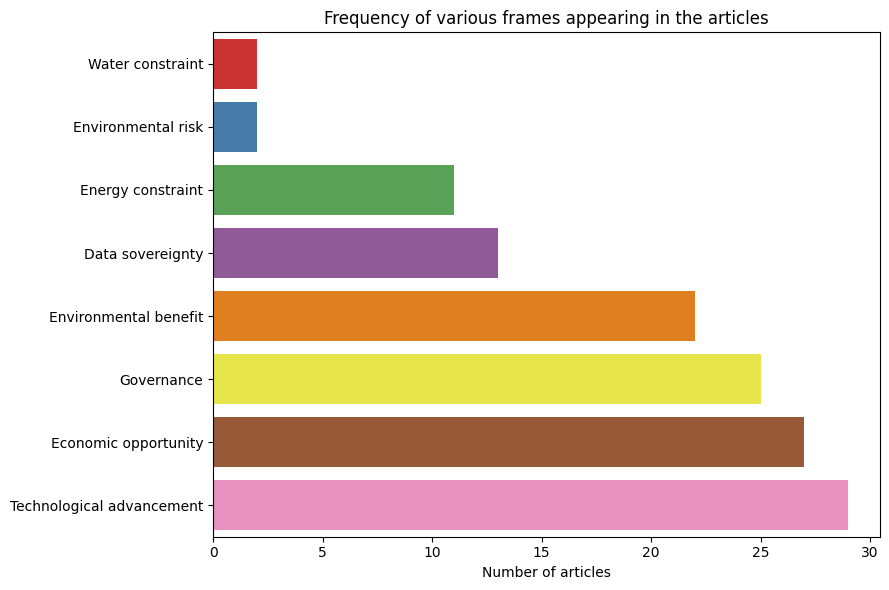

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

frame_names = {
    "economic_frame": "Economic opportunity",
    "technology_frame": "Technological advancement",
    "data_sovereignty_frame": "Data sovereignty",
    "environmental_benefit_frame": "Environmental benefit",
    "environmental_risk_frame": "Environmental risk",
    "energy_constraint_frame": "Energy constraint",
    "water_constraint_frame": "Water constraint",
    "governance_frame": "Governance"
}

frame_plot = (clean_articles[frame_columns]
              .sum()
              .rename(index = frame_names)
              .sort_values())

plt.figure(figsize=(9, 6))

sns.barplot(
    x=frame_plot.values,
    y=frame_plot.index,
    hue=frame_plot.index,
    palette="Set1",
    legend=False
)

plt.xlabel("Number of articles")
plt.ylabel("")
plt.title("Frequency of various frames appearing in the articles")
plt.tight_layout()
plt.show()

# Bag-of-Words

In [35]:
from sklearn.feature_extraction.text import CountVectorizer

mongolian_stopwords = {
    "нь", "ын", "ийн", "ыг", "ийг", "д", "т", "аас", "ээс",
    "оос", "өөс", "тай", "тэй", "той", "болон", "ба", "бөгөөд",
    "юм", "байна", "байгаа", "гэсэн", "гэж"
}

vectorizer = CountVectorizer(
    binary=True,
    ngram_range=(1, 1),
    lowercase=True,
    stop_words=list(mongolian_stopwords)
)

matrix = vectorizer.fit_transform(
    clean_articles["clean_text"]
)

bag_of_words_dataframe = pd.DataFrame(
    matrix.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=clean_articles["article_id"]
)

bag_of_words_dataframe

,08,10,100,11,110,12,13,130,14,15,...,өөрсдөө,өөрчлөгдөж,өөрчлөлт,өөрчлөлтийг,өөрчлөлтийн,өөрчлөлттэй,өөрчлөлтөд,өөрчлөх,өөрөө,өөрөөр
article_id,,,,,,,,,,,,,,,,,,,,,
A001,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A002,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A003,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A004,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A005,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A006,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A011,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A012,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
A013,0,0,0,0,0,0,0,0,0,0,...,0,1,0,1,0,1,0,0,1,1


In [90]:
bag_of_words_frequency = bag_of_words_dataframe.sum().sort_values(ascending=False)

bag_of_words_frequency.head(20)

,0
монгол,32
дата,32
ногоон,32
төв,31
хөрөнгө,30
улсын,30
улс,29
хиймэл,29
эрчим,28
олон,28


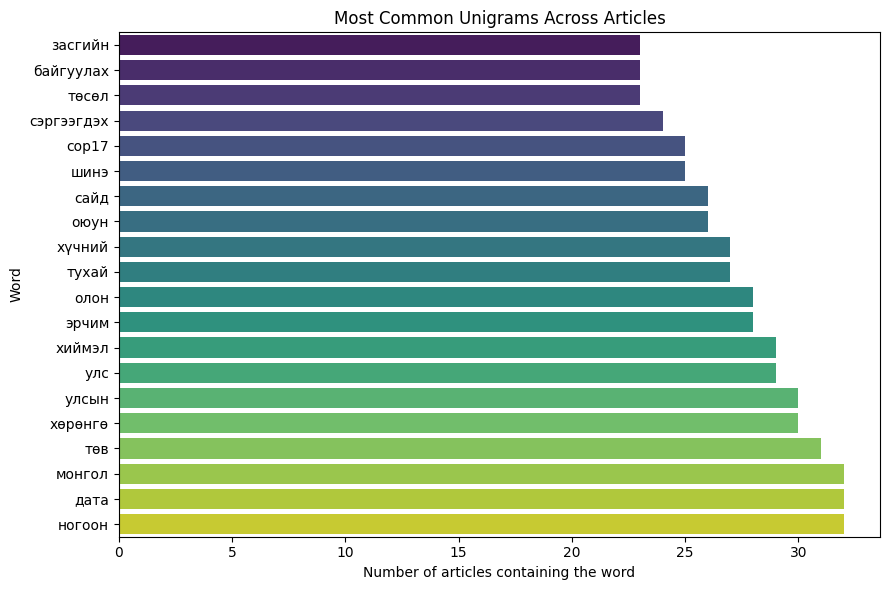

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

top_words = bag_of_words_frequency.head(20).sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_words.values,
    y=top_words.index,
    hue=top_words.index,
    palette="viridis",
    legend=False
)

plt.xlabel("Number of articles containing the word")
plt.ylabel("Word")
plt.title("Most Common Unigrams Across Articles")
plt.tight_layout()
plt.show()

# Tf-idf

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    lowercase=True,
    min_df=1,
    stop_words=list(mongolian_stopwords)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(
    clean_articles["clean_text"]
)

tfidf_dataframe = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=clean_articles["article_id"]
)

tfidf_dataframe

,08,08 17,08 26,08 дугаар,08 сарын,10,10 байгууллага,10 санамж,10 хүртэлх,100,...,өөрөө асар,өөрөө барьж,өөрөө бүх,өөрөө дата,өөрөө монголын,өөрөө одоо,өөрөө цахим,өөрөө эцсийн,өөрөөр,өөрөөр хэлбэл
article_id,,,,,,,,,,,,,,,,,,,,,
A001,0.072905,0.000000,0.000000,0.000000,0.091384,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A002,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A003,0.000000,0.000000,0.000000,0.000000,0.000000,0.069652,0.000000,0.075872,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A004,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A005,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A006,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A011,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A012,0.000000,0.000000,0.000000,0.000000,0.000000,0.037256,0.000000,0.040583,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
A013,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.016492,0.000000,0.000000,0.016492,0.023530,0.023530


In [39]:
mean_tfidf = tfidf_dataframe.mean().sort_values(ascending=False)

mean_tfidf.head(20)

,0
эрчим,0.082224
дата,0.080782
монгол,0.077120
улсын,0.055422
төв,0.052339
ногоон,0.051581
хиймэл,0.050742
хөрөнгө,0.050297
дэд,0.044415
хүчний,0.044260


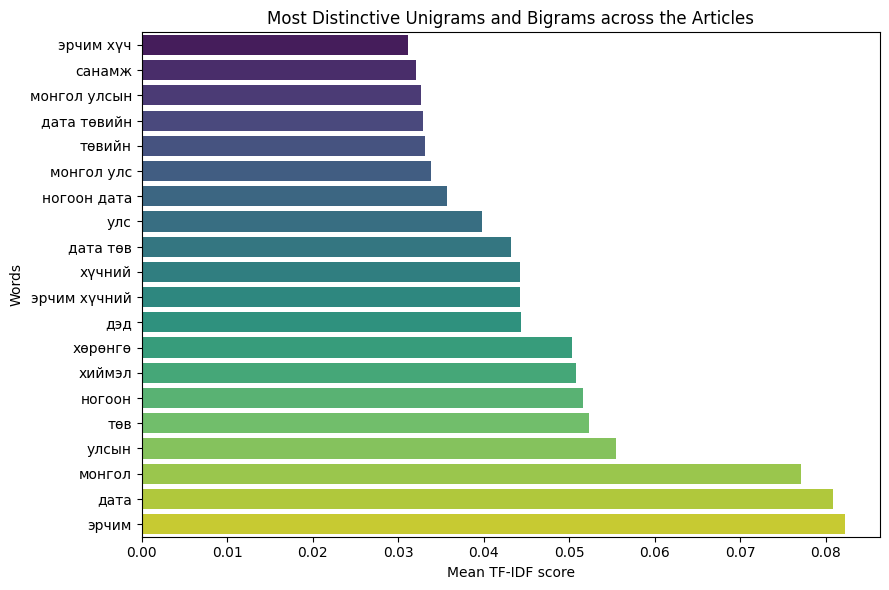

In [40]:
top_tfidf = mean_tfidf.head(20).sort_values()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_tfidf.values,
    y=top_tfidf.index,
    hue=top_tfidf.index,
    palette="viridis",
    legend=False
)

plt.xlabel("Mean TF-IDF score")
plt.ylabel("Words")
plt.title("Most Distinctive Unigrams and Bigrams across the Articles")
plt.tight_layout()
plt.show()

# Translated terms

In [92]:
translations = {
    # Last week's terms
    "хүчин": "Capacity / power",
    "сэргээгдэх": "Renewable",
    "улс": "Country",
    "технологийн": "Technology / technological",
    "олон": "Many",
    "хүрээнд": "Within the framework",
    "санамж": "Memorandum",
    "монгол улсын": "Mongolia’s",
    "cop17": "COP17",
    "ногоон дата": "Green data",
    "дэд": "Infrastructure / sub-",
    "дата төв": "Data center",
    "хөрөнгө": "Investment / capital",
    "хиймэл": "Artificial",
    "ногоон": "Green",
    "төв": "Center",
    "улсын": "Country’s",
    "монгол": "Mongolia",
    "эрчим": "Energy",
    "дата": "Data",
    "оюуны": "Intelligence",
    "талуудын": "Parties’",
    "хамтын": "Cooperative / joint",
    "оруулалт": "Investment / contribution",
    "тухай": "About",
    "хөгжлийн": "Development",
    "сайд": "Minister",

    # New terms this week
    "хүчний": "Power / energy (possessive)",
    "эрчим хүчний": "Energy / electricity (possessive)",
    "эрчим хүч": "Energy / electricity",
    "монгол улс": "Mongolia",
    "төвийн": "Center’s / of the center",
    "дата төвийн": "Data center’s / of the data center",
    "оюун": "Intelligence / mind",
    "шинэ": "New",
    "төсөл": "Project",
    "засгийн": "Government’s",
}

In [93]:
def translate_label(term):
    english = translations.get(term, term)
    return f"{term} — {english}"

# Both graphs in one

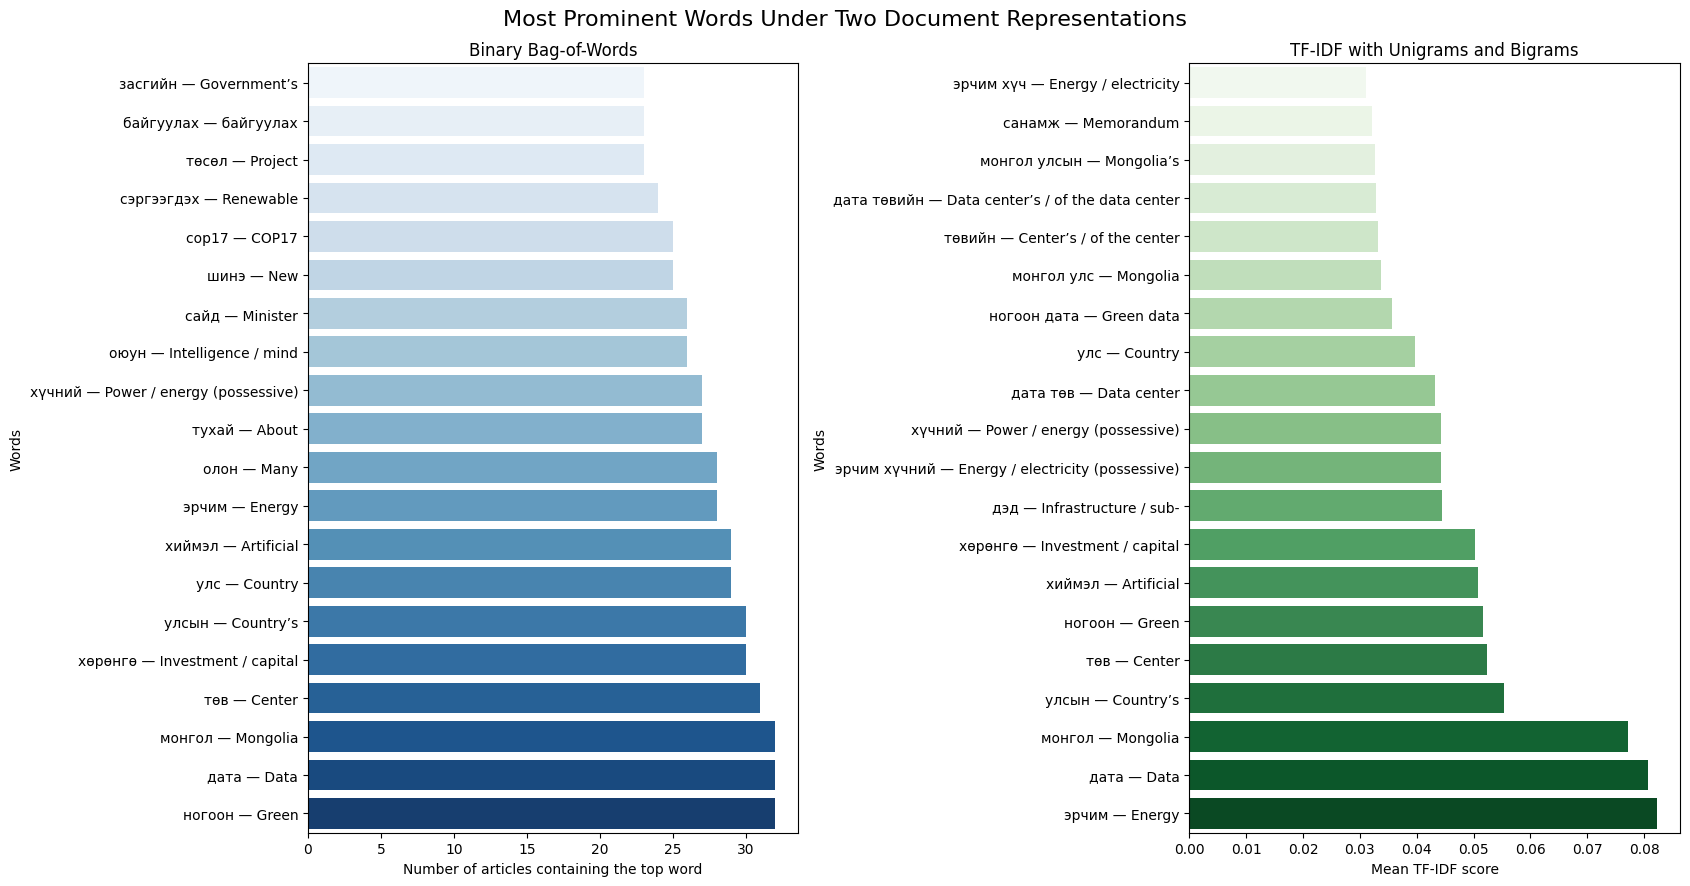

In [95]:
# Select the top 20 and translate labels
top_bag_of_words = bag_of_words_frequency.head(20).sort_values()
top_tfidf = mean_tfidf.head(20).sort_values()

top_bag_of_words.index = [translate_label(term) for term in top_bag_of_words.index]
top_tfidf.index = [translate_label(term) for term in top_tfidf.index]

fig, axes = plt.subplots(1, 2, figsize=(17, 9))

# Bag-of-words
sns.barplot(
    x=top_bag_of_words.values,
    y=top_bag_of_words.index,
    hue=top_bag_of_words.index,
    palette="Blues",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Binary Bag-of-Words")
axes[0].set_xlabel("Number of articles containing the top word")
axes[0].set_ylabel("Words")

# TF-IDF
sns.barplot(
    x=top_tfidf.values,
    y=top_tfidf.index,
    hue=top_tfidf.index,
    palette="Greens",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("TF-IDF with Unigrams and Bigrams")
axes[1].set_xlabel("Mean TF-IDF score")
axes[1].set_ylabel("Words")

fig.suptitle(
    "Most Prominent Words Under Two Document Representations",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "bow_tfidf_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Creating frame dictionaries using stems and phrases from the top words found from the Bag-of-Words and Tf-idf

*   \w* permits different endings.
*   \s+ permits one or more spaces between words.

In [96]:
frame_dictionary = {
    "economic_proxy": [
        r"хөрөнгө\s+оруулалт\w*",
        r"хөрөнгө\s+оруулагч\w*",
        r"эдийн\s+зас\w*",
        r"санхүүжилт\w*",
        r"орлого\s+олох",
        r"экспорт\w*",
    ],

    "technology_proxy": [
        r"хиймэл\s+оюун\w*",
        r"технолог\w*",
        r"дэд\s+бүтэц",
        r"өндөр\s+хүчин\s+чадал\w*",
        r"өгөгдөл\s+хадгал\w*",
        r"тооцоол\w*",
        r"дижитал\s+шилжилт\w*",
    ],

    "data_sovereignty_proxy": [
        r"дижитал\s+бие\s+даасан\s+байдал",
        r"өгөгдлийн\s+тусгаар\s+тогтнол",
        r"өгөгдл\w*\s+дотооддоо\s+хадгал\w*",
        r"өгөгдл\w*\s+монгол\w*\s+хадгал\w*",
        r"өгөгдл\w*\s+хамгаал\w*",
        r"sovereign\s+by\s+design",
    ],

    "environmental_benefit_proxy": [
        r"сэргээгдэх\s+эрчим\s+хүч\w*",
        r"эрчим\s+хүчний\s+хэмнэлт\w*",
        r"эрчим\s+хүчний\s+үр\s+ашиг\w*",
        r"цэвэр\s+эрчим\s+хүч\w*",
        r"нүүрстөрөгчийн\s+ялгар\w*\s+бууруул\w*",
        r"илүүдэл\s+дулаан\w*\s+дахин\s+ашигла\w*",
    ],

    "environmental_risk_proxy": [
        r"байгаль\s+орчны\s+сөрөг\s+нөлөө",
        r"нүүрстөрөгчийн\s+ялгар\w*",
        r"агаарын\s+бохирдол",
        r"нүүрсээр\s+үйлдвэрлэсэн\s+цахилгаан",
        r"экологийн\s+эрсдэл",
    ],

    "energy_constraint_proxy": [
        r"эрчим\s+хүчний\s+дутагдал",
        r"эрчим\s+хүчний\s+хомсдол",
        r"цахилгаан\s+хангамжийн\s+найдвартай\s+байдал",
        r"эрчим\s+хүчээр\s+хангах\s+боломжгүй",
        r"шинэ\s+эрчим\s+хүчний\s+эх\s+үүсвэр",
        r"тусгай\s+зориулалтын\s+эрчим\s+хүчний\s+дэд\s+бүтэц",
    ],

    "water_constraint_proxy": [
        r"усны\s+хомсдол",
        r"усны\s+хэрэглээ",
        r"хөргөлтийн\s+ус",
        r"бага\s+ус\s+хэрэглэдэг\s+хөргөлт",
    ],

    "governance_proxy": [
        r"санамж\s+бичиг\w*",
        r"хамтын\s+ажиллагаа",
        r"засгийн\s+газ\w*",
        r"өгөгдлийн\s+тухай\s+хууль\w*",
        r"хууль\s+эрх\s+зүйн\s+орчин\w*",
        r"бодлогын\s+арга\s+хэмжээ\w*",
    ],
}

In [97]:
import re

# Creating a function that finds any of the patterns in the frame dictionary

def contains_any_pattern(text, patterns):
    text = str(text).lower()

    return int(any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in patterns
    ))

for frame, patterns in frame_dictionary.items():
    clean_articles[frame] = clean_articles["clean_text"].apply(
        lambda text: contains_any_pattern(text, patterns)
    )

In [98]:
# Adding the proxy columns to the clean_articles sheet

proxy_columns = list(frame_dictionary.keys())

clean_articles[
    ["article_id"] + proxy_columns
]

,article_id,economic_proxy,technology_proxy,data_sovereignty_proxy,environmental_benefit_proxy,environmental_risk_proxy,energy_constraint_proxy,water_constraint_proxy,governance_proxy
0,A001,1,1,0,1,0,0,0,0
1,A002,0,1,0,1,0,0,0,0
2,A003,1,1,1,1,0,0,0,1
3,A004,1,1,0,1,0,0,0,1
4,A005,1,1,0,1,0,0,0,1
5,A006,1,1,0,1,0,0,0,1
6,A011,1,1,0,1,0,0,0,1
7,A012,1,1,0,1,0,0,0,1
8,A013,1,1,1,1,0,0,1,1
9,A014,1,0,0,0,0,0,0,0


In [99]:
# Counting how many articles has the frames that were built from
# the dictionary proxy and estimating their percentage
proxy_frame_summary = pd.DataFrame({
    "article_count": clean_articles[proxy_columns].sum(),
    "percentage": clean_articles[proxy_columns].mean().mul(100).round(1)
})

proxy_frame_summary

,article_count,percentage
economic_proxy,31,93.9
technology_proxy,30,90.9
data_sovereignty_proxy,9,27.3
environmental_benefit_proxy,28,84.8
environmental_risk_proxy,4,12.1
energy_constraint_proxy,4,12.1
water_constraint_proxy,4,12.1
governance_proxy,25,75.8


In [109]:
print(frame_columns)

['economic_frame', 'technology_frame', 'data_sovereignty_frame', 'environmental_benefit_frame', 'environmental_risk_frame', 'energy_constraint_frame', 'water_constraint_frame', 'governance_frame']


In [108]:
# Comparing the frame findings from human-coded assignment and dictionary-based frame proxy

comparison = pd.DataFrame(index=clean_articles.index)

for frame in frame_columns:
    name = frame.removesuffix("_frame")  # "economic_frame" -> "economic"
    comparison[f"human_coded_{name}"] = clean_articles[frame]
    comparison[f"keyword_{name}"] = clean_articles[f"{name}_proxy"]

comparison.head()

,human_coded_economic,keyword_economic,human_coded_technology,keyword_technology,human_coded_data_sovereignty,keyword_data_sovereignty,human_coded_environmental_benefit,keyword_environmental_benefit,human_coded_environmental_risk,keyword_environmental_risk,human_coded_energy_constraint,keyword_energy_constraint,human_coded_water_constraint,keyword_water_constraint,human_coded_governance,keyword_governance
0,1,1,1,1,0,0,0,1,0,0,1,0,0,0,0,0
1,1,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0
2,1,1,1,1,0,1,0,1,0,0,0,0,0,0,0,1
3,0,1,1,1,0,0,1,1,0,0,0,0,0,0,1,1
4,1,1,0,1,0,0,0,1,0,0,0,0,0,0,0,1


In [114]:
# Comparing the frequency of frames appearing in the articles based on both presentations

count_comparison = pd.DataFrame(
    {
        "Human-coded": [
            clean_articles[frame].sum()
            for frame in frame_columns
        ],
        "Top-term proxies": [
            clean_articles[f"{frame.removesuffix('_frame')}_proxy"].sum()
            for frame in frame_columns
        ],
    },
    index=frame_columns,
)

count_comparison

,Human-coded,Top-term proxies
economic_frame,27,31
technology_frame,29,30
data_sovereignty_frame,13,9
environmental_benefit_frame,22,28
environmental_risk_frame,2,4
energy_constraint_frame,11,4
water_constraint_frame,2,4
governance_frame,25,25


# Preprocessing Sensitivity

Inspecting how the TF-IDF representation technique is sensitive without the use of stopwords or the n-grams being different

In [128]:
def get_top_tfidf(texts, stopwords=None, ngram_range=(1, 1), n=20):
    vectorizer = TfidfVectorizer(
        stop_words=stopwords,
        ngram_range=ngram_range
    )

    matrix = vectorizer.fit_transform(texts)
    scores = matrix.mean(axis=0).A1
    terms = vectorizer.get_feature_names_out()

    return list(
        terms[scores.argsort()[::-1][:n]]
    )

# Original Version: Stopwords, n-gram range being 1:2
top_tfidf_original = get_top_tfidf(
    clean_articles["clean_text"],
    stopwords=list(mongolian_stopwords),
    ngram_range=(1, 2)
)

# No Stopwords Version: No stopwords, n-gram range being 1:1
top_tfidf_no_stopwords = get_top_tfidf(
    clean_articles["clean_text"],
    stopwords=None,
    ngram_range=(1, 1)
)

# Unigram Version: Stopwords, n-gram range being 1:1
top_tfidf_unigram = get_top_tfidf(
    clean_articles["clean_text"],
    stopwords=list(mongolian_stopwords),
    ngram_range=(1, 1)
)

Inspecting how the Bag-of-Words representation technique is sensitive without the use of stopwords or the n-grams being different

In [133]:
def get_top_bow(texts, stopwords=None, ngram_range=(1, 1), n=20):
    vectorizer = CountVectorizer(
        binary = True,
        stop_words=list(stopwords) if stopwords is not None else None,
        ngram_range=ngram_range
    )

    matrix = vectorizer.fit_transform(texts)
    scores = matrix.mean(axis=0).A1
    terms = vectorizer.get_feature_names_out()

    return list(
        terms[scores.argsort()[::-1][:n]]
    )

# Original Version: Mongolian stopwords, n-gram range being 1:1
top_bow_original = get_top_bow(
    clean_articles["clean_text"],
    stopwords=mongolian_stopwords,
    ngram_range=(1, 1)
)

# No Stopwords Version: No stopwords, n-gram range being 1:1
top_bow_no_stopwords = get_top_bow(
    clean_articles["clean_text"],
    stopwords=None,
    ngram_range=(1, 1)
)

# Bigram Version: Mongolian stopwords, n-gram range being 1:2
top_bow_bigrams = get_top_bow(
    clean_articles["clean_text"],
    stopwords=mongolian_stopwords,
    ngram_range=(1, 2)
)

Estimating the Jaccard similarity coefficient
$$
J(A,B) = \frac{|A \cap B|}{|A \cup B|}
$$

0 = no shared terms

1 = exactly the same terms

0.5 = moderate overlap

In [129]:
def jaccard(list1, list2):
    set1, set2 = set(list1), set(list2)
    return len(set1 & set2) / len(set1 | set2)

# Comparing TF-IDF results across preprocessing choices
print("Original vs No stopwords:", jaccard(top_tfidf_original, top_tfidf_no_stopwords))
print("Original vs Unigram:", jaccard(top_tfidf_original, top_tfidf_unigram))
print("No stopwords vs Unigram:", jaccard(top_tfidf_no_stopwords, top_tfidf_unigram))

Original vs No stopwords: 0.5384615384615384
Original vs Unigram: 0.5384615384615384
No stopwords vs Unigram: 0.6666666666666666


In [134]:
# Comparing Bag-of-Words results across preprocessing choices
print("Original vs No stopwords:", jaccard(top_bow_original, top_bow_no_stopwords))
print("Original vs Bigram:", jaccard(top_bow_original, top_bow_bigrams))
print("No stopwords vs Bigram:", jaccard(top_bow_no_stopwords, top_bow_bigrams))

Original vs No stopwords: 0.6
Original vs Bigram: 0.48148148148148145
No stopwords vs Bigram: 0.48148148148148145


In [118]:
frame_columns

['economic_frame',
 'technology_frame',
 'data_sovereignty_frame',
 'environmental_benefit_frame',
 'environmental_risk_frame',
 'energy_constraint_frame',
 'water_constraint_frame',
 'governance_frame']

# Agreement between human-coded framing and dictionary-based proxies

In [120]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparisons = {
    "Economic": ("economic_frame", "economic_proxy"),
    "Technology": ("technology_frame", "technology_proxy"),
    "Data Sovereignty Frame": ("data_sovereignty_frame", "data_sovereignty_proxy"),
    "Environmental benefit": (
        "environmental_benefit_frame",
        "environmental_benefit_proxy"
    ),
    "Environmental risk": (
        "environmental_risk_frame",
        "environmental_risk_proxy"
    ),
    "Energy constraint": (
        "energy_constraint_frame",
        "energy_constraint_proxy"
    ),
    "Water constraint": (
        "water_constraint_frame",
        "water_constraint_proxy"
    ),
    "Governance": ("governance_frame", "governance_proxy")
}

results = []

for frame, (manual, proxy) in comparisons.items():
    results.append({
        "frame": frame,
        "precision": precision_score(
            clean_articles[manual],
            clean_articles[proxy],
            zero_division=0
        ),
        "recall": recall_score(
            clean_articles[manual],
            clean_articles[proxy],
            zero_division=0
        ),
        "f1": f1_score(
            clean_articles[manual],
            clean_articles[proxy],
            zero_division=0
        )
    })

diagnostic_results = pd.DataFrame(results)
diagnostic_results

,frame,precision,recall,f1
0,Economic,0.838710,0.962963,0.896552
1,Technology,0.900000,0.931034,0.915254
2,Data Sovereignty Frame,0.888889,0.615385,0.727273
3,Environmental benefit,0.785714,1.000000,0.880000
4,Environmental risk,0.250000,0.500000,0.333333
5,Energy constraint,1.000000,0.363636,0.533333
6,Water constraint,0.500000,1.000000,0.666667
7,Governance,0.920000,0.920000,0.920000


**Precision:** When the dictionary detects a frame, how often does manual coding agree?

**Recall:** How many manually identified frames does the dictionary capture?

**F1:** A summary of precision and recall.

# Visualization of the Comparison between Human-Coded and Dictionary-Based Frame Finding Techniques

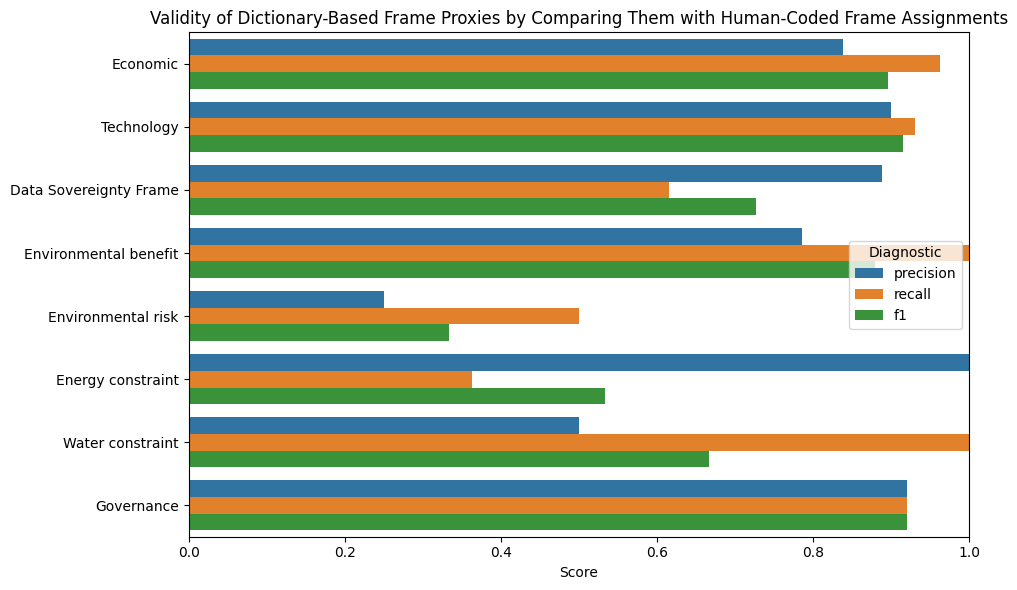

In [136]:
plot_data = diagnostic_results.melt(
    id_vars="frame",
    var_name="Diagnostic",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_data,
    x="Score",
    y="frame",
    hue="Diagnostic"
)

plt.xlim(0, 1)
plt.xlabel("Score")
plt.ylabel("")
plt.title("Validity of Dictionary-Based Frame Proxies by Comparing Them with Human-Coded Frame Assignments")
plt.tight_layout()

plt.savefig(
    "validity_of_dictionary_based_proxies.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()